# RFM analyze - (Recency, Frequency, Monetary)

In [1]:
from datetime import datetime

import io
from io import StringIO

import pydotplus
import summary
from pydotplus import graph_from_dot_data

from bleach import clean

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import shapiro, normaltest, anderson

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import silhouette_score, accuracy_score
from sklearn. tree import export_graphviz
from sklearn.cluster import KMeans, MiniBatchKMeans


from math import log

In [2]:
data = pd.read_csv('online_retail.csv')

In [3]:
data.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [4]:
data.tail()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France
1067370,581587,POST,POSTAGE,1,2011-12-09 12:50:00,18.00,12680.0,France


In [5]:
data.sample(5)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
100589,498900,22025,RING OF ROSES BIRTHDAY CARD,12,2010-02-23 13:59:00,0.42,15241.0,United Kingdom
527546,536557,85232B,SET OF 3 BABUSHKA STACKING TINS,1,2010-12-01 14:41:00,4.95,17841.0,United Kingdom
442089,531489,22846,BREAD BIN DINER STYLE RED,1,2010-11-08 15:02:00,34.00,NaN,United Kingdom
437979,531262,15060B,FAIRY CAKE DESIGN UMBRELLA,3,2010-11-07 11:45:00,3.75,17068.0,United Kingdom
126044,501442,21527,RETRO SPOT TRADITIONAL TEAPOT,6,2010-03-16 13:47:00,7.95,12835.0,United Kingdom


In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  str    
 1   StockCode    1067371 non-null  str    
 2   Description  1062989 non-null  str    
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  str    
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 65.1 MB


In [7]:
data.describe()

,Quantity,Price,Customer ID
count,1.067371e+06,1.067371e+06,824364.000000
mean,9.938898e+00,4.649388e+00,15324.638504
std,1.727058e+02,1.235531e+02,1697.464450
min,-8.099500e+04,-5.359436e+04,12346.000000
25%,1.000000e+00,1.250000e+00,13975.000000
50%,3.000000e+00,2.100000e+00,15255.000000
75%,1.000000e+01,4.150000e+00,16797.000000
max,8.099500e+04,3.897000e+04,18287.000000


In [8]:
data.shape

(1067371, 8)

In [9]:
data.isna().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [10]:
null_df = data.isnull().sum().reset_index()
null_df.head()
null_df = null_df.rename(
    columns={
        0: 'nan_values',
        'index': 'column_name'})

total_len_df = data.shape[0]

null_df['nan_percentage'] = round(null_df['nan_values']/total_len_df*100, 2)
print(null_df)


   column_name  nan_values  nan_percentage
0      Invoice           0            0.00
1    StockCode           0            0.00
2  Description        4382            0.41
3     Quantity           0            0.00
4  InvoiceDate           0            0.00
5        Price           0            0.00
6  Customer ID      243007           22.77
7      Country           0            0.00


In [11]:
data = data.dropna()
data.reset_index()

,index,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
...,...,...,...,...,...,...,...,...,...
824359,1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
824360,1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
824361,1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
824362,1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


In [12]:
data[data['Invoice'].str.contains('C')].head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia


In [13]:
data['InvoiceDate'].max()

'2011-12-09 12:50:00'

In [14]:
clean_data = data[~(data['Invoice'].str.contains('C'))]

# RFM metrics for client

In [15]:
clean_data['Amount'] = clean_data['Quantity'] * clean_data['Price']

In [16]:
customers_data = clean_data.groupby('Customer ID').agg(
    frequency=('Invoice', 'nunique'),
    last_purchase=('InvoiceDate', 'max'),
    amount=('Amount', 'sum')
).reset_index()

customers_data['last_purchase'] = pd.to_datetime(
    customers_data['last_purchase'],
    format='%Y-%m-%d %H:%M:%S'
)
customers_data['recency'] = datetime(2011, 12, 11) - customers_data['last_purchase']
customers_data['recency'] = customers_data['recency'].dt.days
customers_data = customers_data.drop(columns=['last_purchase'])
customers_data.head()

,Customer ID,frequency,amount,recency
0,12346.0,12,77556.46,326
1,12347.0,8,5633.32,3
2,12348.0,5,2019.40,76
3,12349.0,4,4428.69,19
4,12350.0,1,334.40,311


In [17]:
customers_data.describe()

,Customer ID,frequency,amount,recency
count,5881.000000,5881.000000,5881.000000,5881.000000
mean,15314.674205,6.287196,3017.076888,201.992858
std,1715.429759,13.012879,14734.128619,209.489651
min,12346.000000,1.000000,0.000000,1.000000
25%,13833.000000,1.000000,347.800000,26.000000
50%,15313.000000,3.000000,897.620000,96.000000
75%,16797.000000,7.000000,2304.180000,380.000000
max,18287.000000,398.000000,608821.650000,739.000000


In [18]:
print(f'Number of customers: {int(customers_data.describe()["Customer ID"]["count"])}')
print(f'Zero amount of customers: {customers_data[customers_data["amount"] == 0].shape[0]}')
customers_data[customers_data["amount"] == 0].head()

Number of customers: 5881
Zero amount of customers: 3


,Customer ID,frequency,amount,recency
904,13256.0,1,0.0,15
1739,14103.0,1,0.0,666
2458,14827.0,1,0.0,666


In [19]:
customers_data = customers_data[customers_data["amount"] > 0].reset_index(drop=True)

# Gaussian Distribution

$$
f(x) = \frac{1}{\sigma\sqrt{2\pi}}e^{-\frac{(x-\mu)^2}{2\sigma^2}}
$$

In [20]:
def plot_variable_distribution(X, column_name):
    fig, ax = plt.subplots()
    ax.boxplot(x=X, notch=True)
    ax.set_title(f'Boxplot for {column_name}')

    mu = X.mean()
    sigma = X.std()
    num_bins = 50

    fig1, ax1 = plt.subplots()
    n, bins, patches = ax1.hist(X, num_bins, density=True)

    y = ((1 / (np.sqrt(2 * np.pi)*sigma)) * np.exp(-0.5 * (1/sigma*(bins - mu))**2))

    mu = round(mu, 2)
    sigma = round(sigma, 2)

    ax1.plot(bins, y, '--')
    ax1.set_xlabel(column_name)
    ax1.set_ylabel('Density')
    ax1.set_ylabel(f'Histogram of {column_name}: mu {mu}, sigma {sigma}')

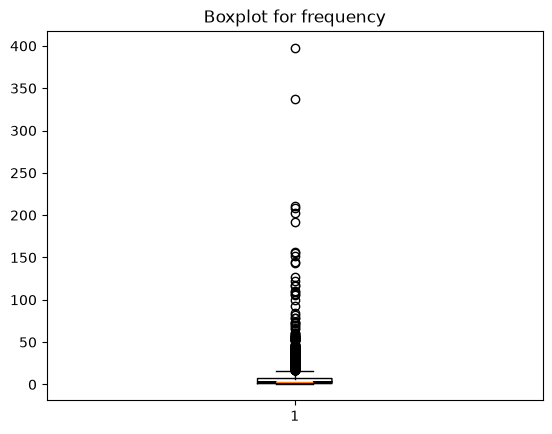

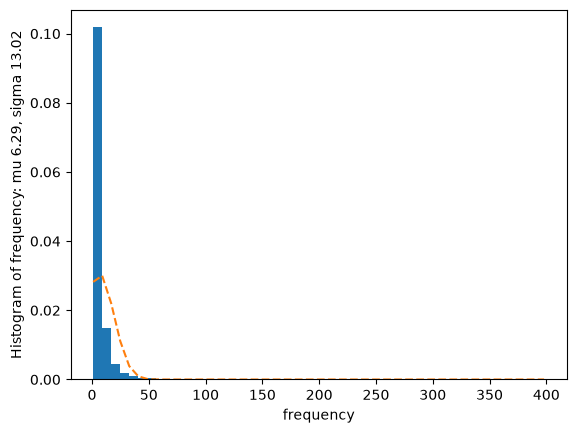

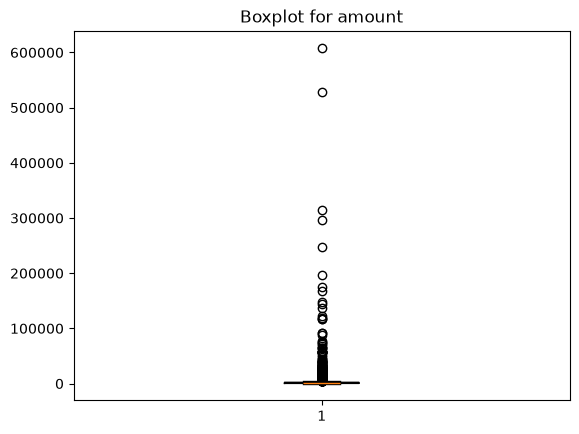

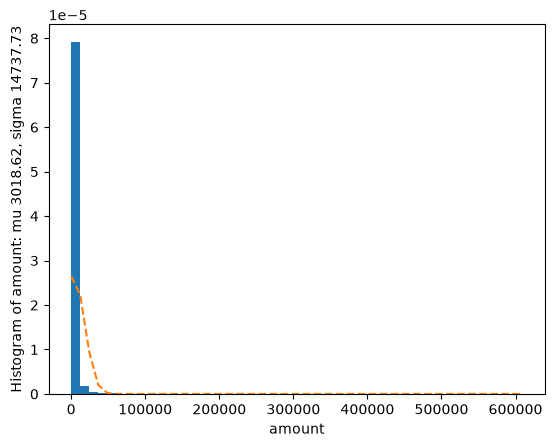

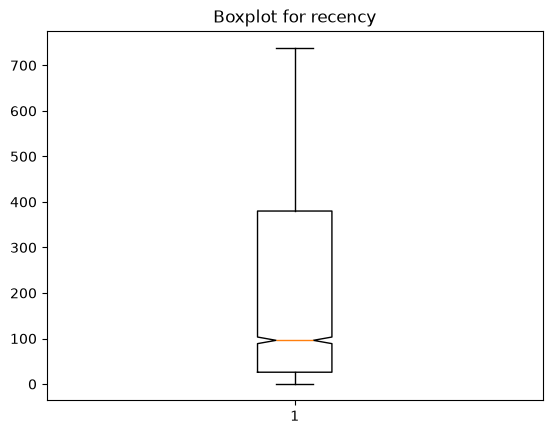

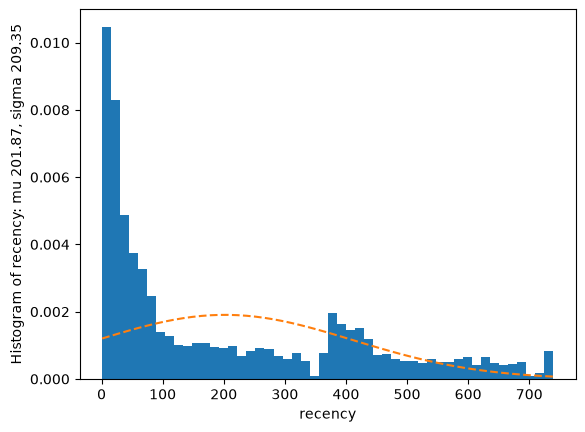

In [21]:
feature_columns = ['frequency', 'amount', 'recency']

for col_name in feature_columns:
    x = customers_data[col_name]
    plot_variable_distribution(x, col_name)

In [22]:
for col_name in feature_columns:

    print(f'Sharipo-Wilk test for {col_name}')
    stat, p = shapiro(customers_data[col_name])
    print('Statistics=%.3f, p=%.3f of %s distribution' % (stat, p, col_name))

    alpha = 0.05
    if p > alpha:
        print(f'Sample of {col_name} looks normal (fail to reject H0) with Sharipo-Wilk Test')
    else:
        print(f'Sample of {col_name} does not look Gaussian (reject H0) with Sharipo-Wilk Test \n\n')

    print(f'D’Agostino’s K^2 test for {col_name}')
    stat, p = normaltest(customers_data[col_name])
    print('Statistics=%.3f, p=%.3f of %s distribution' % (stat, p, col_name))

    alpha = 0.05
    if p > alpha:
        print(f'Sample of {col_name} looks normal (fail to reject H0) with D’Agostino’s K^2 Test')
    else:
        print(f'Sample of {col_name} does not look normal (reject H0) with D’Agostino’s K^2 Test \n\n')

    print(f'Anderson-Darling test for {col_name}')

    result = anderson(customers_data[col_name])
    print('Statistic: %.3f' % result.statistic)
    p = 0
    for i in range(len(result.critical_values)):
        sl, cv = result.significance_level[i], result.critical_values[i]
        if result.statistic < result.critical_values[i]:
            print('%.3f: %.3f, data looks normal (fail to reject H0) with Anderson-Darling test \n\n' % (sl, cv))
        else:
            print('%.3f: %.3f, data does not look normal (reject H0) with Anderson-Darling test \n\n' % (sl, cv))

Sharipo-Wilk test for frequency
Statistics=0.341, p=0.000 of frequency distribution
Sample of frequency does not look Gaussian (reject H0) with Sharipo-Wilk Test 


D’Agostino’s K^2 test for frequency
Statistics=10475.611, p=0.000 of frequency distribution
Sample of frequency does not look normal (reject H0) with D’Agostino’s K^2 Test 


Anderson-Darling test for frequency
Statistic: 945.011
15.000: 0.561, data does not look normal (reject H0) with Anderson-Darling test 


10.000: 0.631, data does not look normal (reject H0) with Anderson-Darling test 


5.000: 0.752, data does not look normal (reject H0) with Anderson-Darling test 


2.500: 0.873, data does not look normal (reject H0) with Anderson-Darling test 


1.000: 1.035, data does not look normal (reject H0) with Anderson-Darling test 


Sharipo-Wilk test for amount
Statistics=0.124, p=0.000 of amount distribution
Sample of amount does not look Gaussian (reject H0) with Sharipo-Wilk Test 


D’Agostino’s K^2 test for amount
Stat

C:\Users\zamanov\Documents\python_ai_FSDM_Oct_24_4_az\AI 20\.venv\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5878.
  res = hypotest_fun_out(*samples, **kwds)
C:\Users\zamanov\AppData\Local\Temp\ipykernel_29444\2717389871.py:25: FutureWarning: As of SciPy 1.17, users must choose a p-value calculation method by providing the `method` parameter. `method='interpolate'` interpolates the p-value from pre-calculated tables; `method` may also be an instance of `MonteCarloMethod` to approximate the p-value via Monte Carlo simulation. When `method` is specified, the result object will include a `pvalue` attribute and not attributes `critical_value`, `significance_level`, or `fit_result`. Beginning in 1.19.0, these other attributes will no longer be available, and a p-value will always be computed according to one of the available `method` options.
  result = anderson(customers_data[col_

| Признак   |  Shapiro-Wilk (p-value) |  D'Agostino (p-value) | Anderson-Darling (statistika) |
|-----------|------------------------:|----------------------:|------------------------------:|
| frequency |                      ≈0 |                    ≈0 |                       945.011 |
| amount    |                      ≈0 |                    ≈0 |                      1552.868 |
| recency   |                      ≈0 |                    ≈0 |                       349.154 |

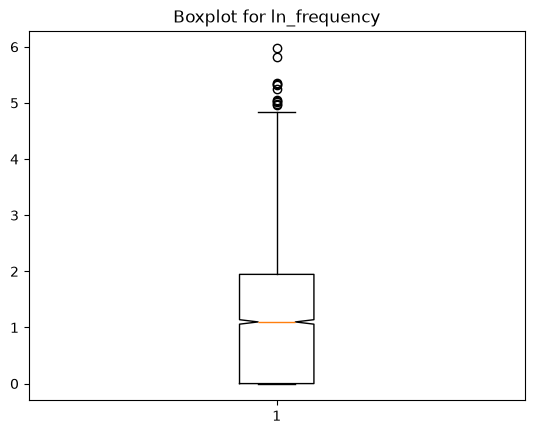

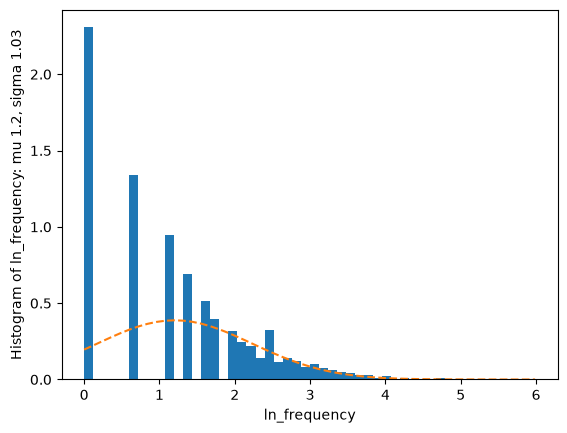

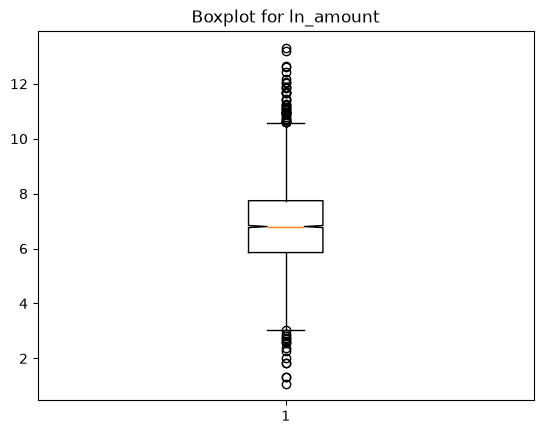

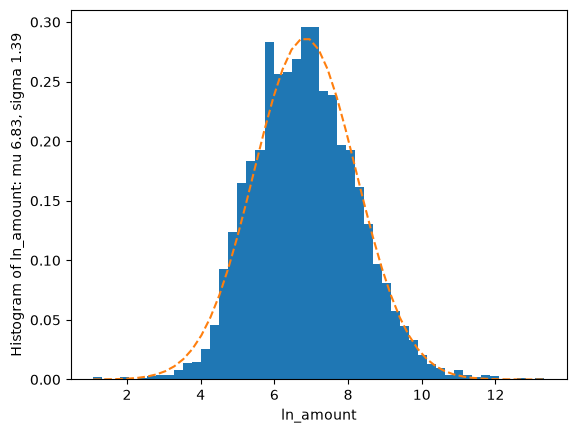

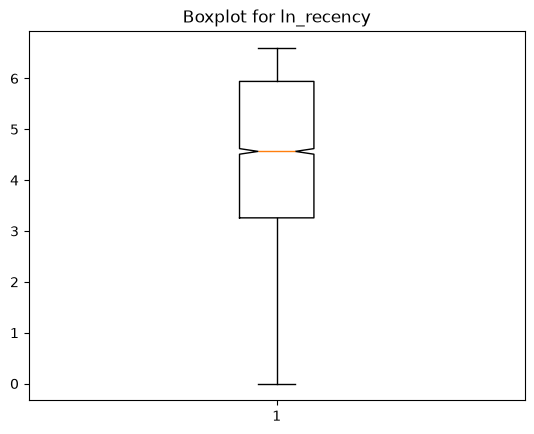

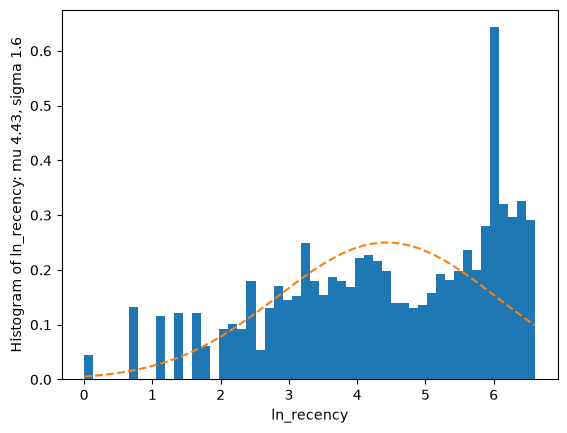

In [23]:
for col_name in feature_columns:
    x = customers_data[col_name]
    ln_x = x.apply(lambda x: log(x))

    ln_col_name = "ln_" + col_name
    plot_variable_distribution(ln_x, ln_col_name)

In [24]:
customers_data['r'] = customers_data['recency'].apply(lambda x: log(x)) # son alışdan keçən müddət
customers_data['f'] = customers_data['frequency'].apply(lambda x: log(x)) # alış tezliyi
customers_data['m'] = customers_data['amount'].apply(lambda x: log(x)) # məbləğ

In [25]:
use_data = customers_data[['Customer ID', 'r', 'f', 'm']]
use_data.head()

,Customer ID,r,f,m
0,12346.0,5.786897,2.484907,11.258761
1,12347.0,1.098612,2.079442,8.636454
2,12348.0,4.330733,1.609438,7.610556
3,12349.0,2.944439,1.386294,8.395859
4,12350.0,5.739793,0.000000,5.812338


In [26]:
use_data = use_data.set_index("Customer ID")
use_data.head()

,r,f,m
Customer ID,,,
12346.0,5.786897,2.484907,11.258761
12347.0,1.098612,2.079442,8.636454
12348.0,4.330733,1.609438,7.610556
12349.0,2.944439,1.386294,8.395859
12350.0,5.739793,0.000000,5.812338


In [27]:
use_data.shape

(5878, 3)

In [28]:
inertia = []
ss = []

for k in range(2, 15):
    kmeans = KMeans(n_clusters=k, random_state=1).fit(use_data)
    ss.append(silhouette_score(use_data, kmeans.labels_, metric='euclidean'))
    inertia.append(np.sqrt(kmeans.inertia_))

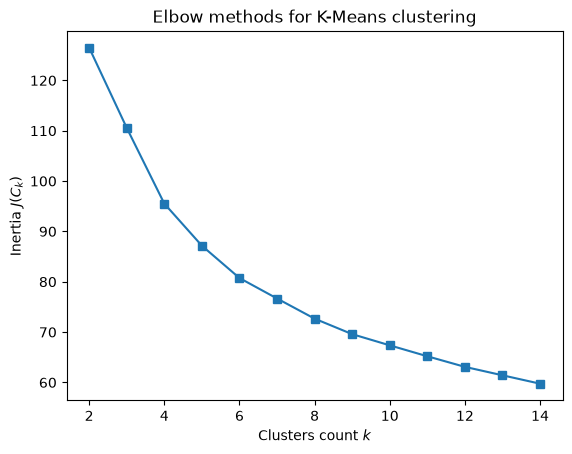

In [29]:
plt.plot(range(2, 15), inertia, marker='s')
plt.xlabel('Clusters count $k$')
plt.ylabel('Inertia $J(C_k)$')
plt.title('Elbow methods for K-Means clustering')
plt.show()

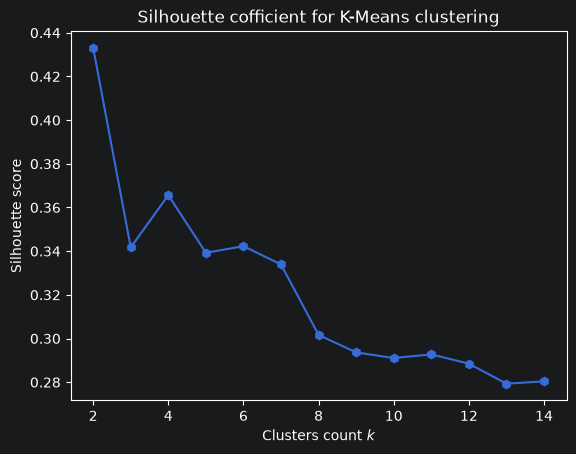

In [257]:
plt.plot(range(2, 15), ss, marker='h')
plt.xlabel('Clusters count $k$')
plt.ylabel('Silhouette score')
plt.title('Silhouette cofficient for K-Means clustering')
plt.show()

In [32]:
C = KMeans(n_clusters=4, random_state=42).fit(use_data)
use_data['cluster'] = C.fit_predict(use_data)

In [33]:
use_data['cluster'] = use_data['cluster'] + 1

In [34]:
use_data['cluster'] = use_data['cluster'].astype(int)

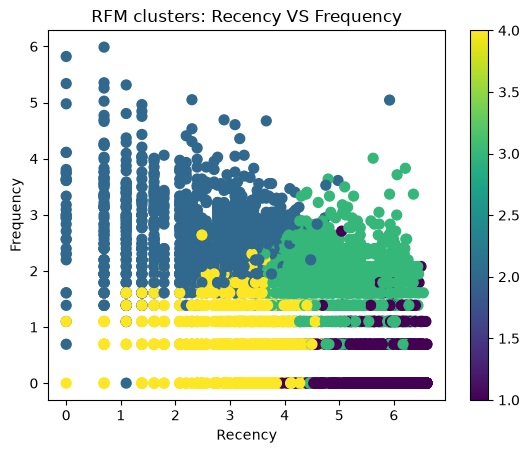

In [35]:
fig = plt.figure()
ax = fig.add_subplot(111)

sct = ax.scatter(use_data['r'], use_data['f'], c=use_data['cluster'], s=50)

ax.set_title('RFM clusters: Recency VS Frequency')
ax.set_xlabel('Recency')
ax.set_ylabel('Frequency')
plt.colorbar(sct)
plt.show()

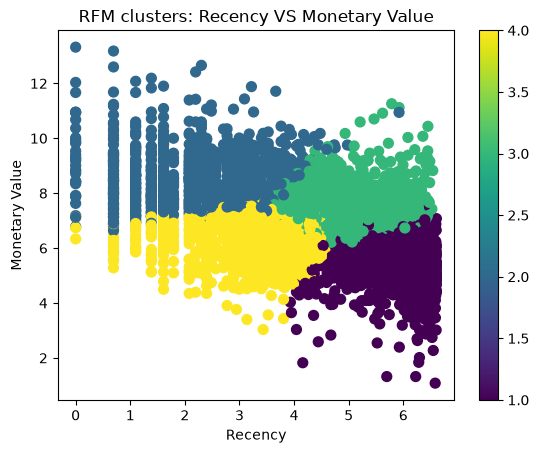

In [36]:
fig = plt.figure()
ax = fig.add_subplot(111)

sct = ax.scatter(use_data['r'], use_data['m'], c=use_data['cluster'], s=50)

ax.set_title('RFM clusters: Recency VS Monetary Value')
ax.set_xlabel('Recency')
ax.set_ylabel('Monetary Value')
plt.colorbar(sct)
plt.show()

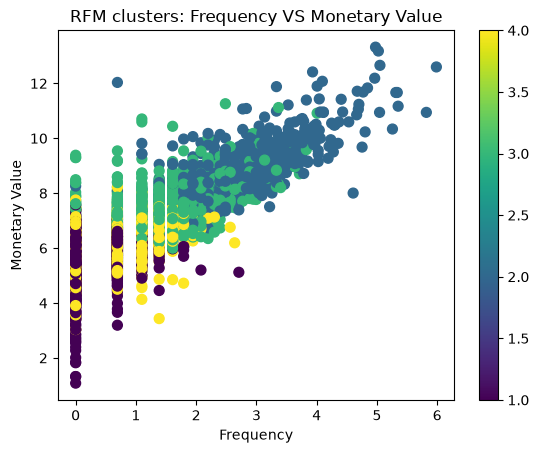

In [37]:
fig = plt.figure()
ax = fig.add_subplot(111)

sct = ax.scatter(use_data['f'], use_data['m'], c=use_data['cluster'], s=50)

ax.set_title('RFM clusters: Frequency VS Monetary Value')
ax.set_xlabel('Frequency')
ax.set_ylabel('Monetary Value')
plt.colorbar(sct)
plt.show()

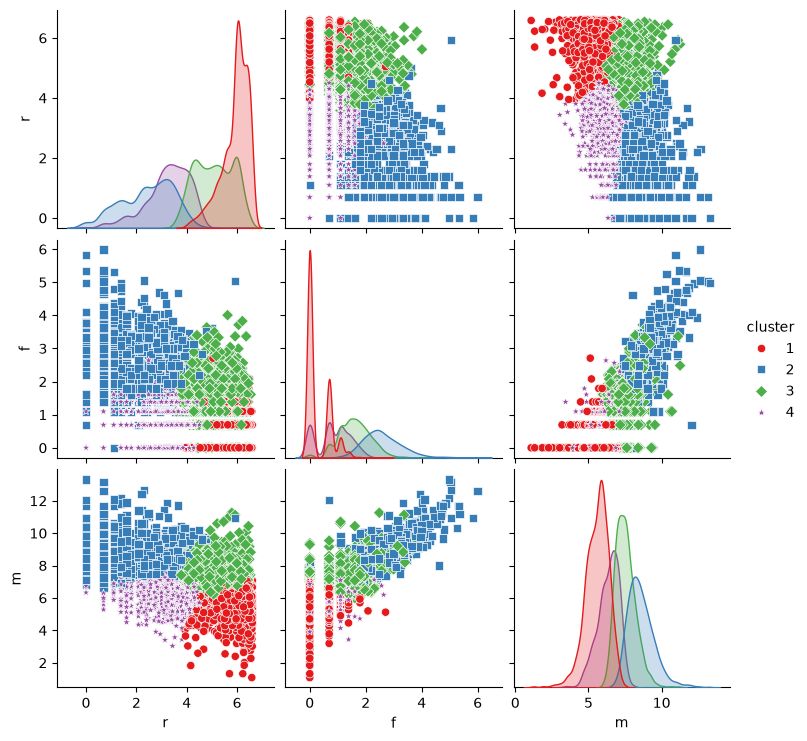

In [38]:
sns.pairplot(use_data, hue='cluster', markers=['o', 's', 'D', '*'],
             palette=sns.color_palette('Set1', n_colors=4))
plt.show()

In [39]:
use_data = use_data.reset_index()

In [40]:
final_data = customers_data.merge(use_data[['Customer ID', 'cluster']], how='inner', on='Customer ID')

In [41]:
final_data = final_data.drop(columns=['r', 'f', 'm'])

In [42]:
final_data.head()

,Customer ID,frequency,amount,recency,cluster
0,12346.0,12,77556.46,326,3
1,12347.0,8,5633.32,3,2
2,12348.0,5,2019.40,76,3
3,12349.0,4,4428.69,19,2
4,12350.0,1,334.40,311,1


In [43]:
print(feature_columns)

['frequency', 'amount', 'recency']


In [46]:
X = final_data[feature_columns]
y = final_data['cluster']

In [47]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [48]:
clf_tree = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
clf_tree = clf_tree.fit(X_train, y_train)

In [49]:
y_pred = clf_tree.predict(X_test)

In [50]:
print(f'Model accuracy: {accuracy_score(y_test, y_pred):.3f}')

Model accuracy: 0.895


In [52]:
import pandas as pd

summary = final_data.groupby('cluster').agg(
    **{
        'Müştəri sayı': ('Customer ID', 'count'),
        'Son alışdan keçən müddət': ('recency', 'mean'),
        'Alış tezliyi': ('frequency', 'mean'),
        'Məbləğ': ('amount', 'mean')
    }
)

cluster_names = {
    1: 'İtirilmiş müştərilər',
    2: 'VIP müştərilər',
    3: 'Yeni və ya təsadüfi müştərilər',
    4: 'Risk altında olan daimi müştərilər'
}

cluster_descriptions = {
    1: 'Uzun müddətdir alış etmirlər, alış tezliyi və məbləği aşağıdır',
    2: 'Yaxın zamanda alış ediblər, alış tezliyi və məbləği yüksəkdir',
    3: 'Yaxın zamanda alış ediblər, lakin nadir hallarda və kiçik məbləğlərdə',
    4: 'Əvvəllər aktiv alış ediblər, lakin uzun müddətdir geri qayıtmırlar'
}

summary['Müştəri tipi'] = summary.index.map(cluster_names)
summary['Təsvir'] = summary.index.map(cluster_descriptions)

summary = summary[
    [
        'Müştəri tipi',
        'Müştəri sayı',
        'Son alışdan keçən müddət',
        'Alış tezliyi',
        'Məbləğ',
        'Təsvir'
    ]
]

display(
    summary.style
    .format({
        'Müştəri sayı': '{:,.0f}',
        'Son alışdan keçən müddət': '{:.1f}',
        'Alış tezliyi': '{:.1f}',
        'Məbləğ': '{:,.2f}'
    })
    .background_gradient(
        subset=[
            'Son alışdan keçən müddət',
            'Alış tezliyi',
            'Məbləğ'
        ],
        cmap='YlGnBu'
    )
    .set_caption('Müştərilərin RFM seqmentasiyası')
)

,Müştəri tipi,Müştəri sayı,Son alışdan keçən müddət,Alış tezliyi,Məbləğ,Təsvir
cluster,,,,,,
1,İtirilmiş müştərilər,"1,938",416.6,1.5,342.00,"Uzun müddətdir alış etmirlər, alış tezliyi və məbləği aşağıdır"
2,VIP müştərilər,"1,182",18.0,18.4,"10,473.56","Yaxın zamanda alış ediblər, alış tezliyi və məbləği yüksəkdir"
3,Yeni və ya təsadüfi müştərilər,"1,501",209.7,5.9,"2,532.78","Yaxın zamanda alış ediblər, lakin nadir hallarda və kiçik məbləğlərdə"
4,Risk altında olan daimi müştərilər,"1,257",34.3,2.7,715.33,"Əvvəllər aktiv alış ediblər, lakin uzun müddətdir geri qayıtmırlar"
